# AVAX SHORT — mean reversion ở dải Bollinger (Bollinger dài hạn, RSI ngắn hạn), train full grid trên GPU

Notebook này dùng `train_full_grid_gpu.py` cùng thư mục (logic chung ở `reference/multi_position/multi_position_engine.py`). Sửa **ô Cấu hình**, rồi chọn **Run All**. Kết quả lưu thành CSV cạnh notebook.

**Ý tưởng:** Bollinger là chỉ báo **dài hạn** (`boll_window` 48–672 nến = 12 giờ → 7 ngày ở 15min), RSI là chỉ báo **ngắn hạn** (`rsi_window` 2–14). Khi giá ra ngoài dải và RSI ở vùng cực, vào lệnh **ngược chiều** với nhịp vừa xảy ra.

**Vào lệnh ở close của nến `i`** — cột `entry_mode`:
- `1` — giá vượt ra ngoài dải: `close[i-1] < upper[i] < close[i]` (đóng cửa vượt lên trên dải trên) **và** `RSI[i] > rsi_threshold`
- `2` — giá quay lại trong dải: `close[i-1] > upper[i] > close[i]` (quay lại trong dải) **và** `RSI[i] > rsi_threshold`

**Risk** = `sl_multiplier × (upper[i] − lower[i])` (độ rộng dải); stop = entry + risk; TP = entry − `tp_sl_ratio` × risk, hoặc dải giữa khi `tp_sl_ratio = -1` (dải giữa = SMA tại nến vào, cố định như lệnh limit; chạm TP ⇒ R = khoảng cách tới dải giữa ÷ risk). Timeout `MAX_HOLDING_BARS` nến; phí vào lệnh `0.001 / sl_ratio` (bỏ lệnh nếu > 0.2R); phí giữ lệnh mỗi 8 giờ (`FEE_BARS = None` ⇒ 32 ở 15min); một lệnh mỗi lúc.

Grid search trên toàn khoảng train là **in-sample**; đánh giá ngoài mẫu bằng `reference/walk_forward_multi_asset.py --folder short_bollinger+RSI+fade` (đọc grid và `SCORE_FORMULA` từ ô Cấu hình này).

In [14]:
# CẤU HÌNH — sửa ô này trước khi chạy
TIMEFRAME = "1h"                 # ví dụ "5min", "15min", "1h", "4h"
START_DATE = "2023-01-01"          # ngày bắt đầu, bao gồm ngày này
END_DATE = "2025-01-01"            # ngày kết thúc, bao gồm ngày này
DATA_CSV = "../data_fx_wf/eurusd_futures_5min.csv"                     # None = reference/data/avaxusdt_futures_5min.csv
SCRIPT_PATH = None                  # None = tự tìm train_full_grid_gpu.py

SCORE_FORMULA = "r_martin_monthly"
# Sửa trực tiếp các danh sách dưới đây để đổi grid. Số bộ tham số là tích số giá trị mỗi danh sách.
# tp_sl_ratio = -1 nghĩa là chốt lời ở dải giữa; entry_mode 1 = vượt ra ngoài dải, 2 = quay lại trong dải.
SEARCH_SPACES = {
    "boll_window": [40, 45, 50, 60, 80, 100, 150, 200, 400],
        "boll_window_dev": [1.8, 2.0, 2.2, 2.5],
        "rsi_window": [5, 7, 9, 14, 20, 30],
        "rsi_threshold": [5, 10, 15, 20, 25, 30, 35, 40],
        "sl_multiplier": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5],
        "tp_sl_ratio": [1.1],
    "entry_mode": [1, 2],
}
LIMIT = None                         # None = toàn bộ bộ tham số; số nguyên để chạy thử
MAX_HOLDING_BARS = 288             # số nến tối đa giữ lệnh theo TIMEFRAME
FEE_BARS = None                    # None = 8 giờ mỗi lần phí (32 ở 15min)
VERIFY_SAMPLES = 0                  # 0 = bỏ qua so với CPU; ví dụ 8 = kiểm tra 8 bộ
MIN_TRADES = 40                     # bảng xếp hạng chỉ giữ bộ có ít nhất số lệnh này
OUTPUT_CSV = None                   # None = CSV theo timeframe, cạnh notebook

In [15]:
# Nạp script cùng thư mục (cũng hoạt động khi kernel bắt đầu ở thư mục khác trong repo)
from pathlib import Path
import importlib.util
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SIDE_FOLDER = "short_bollinger+RSI+fade"
if SCRIPT_PATH is None:
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        if parent.name == SIDE_FOLDER:
            candidates.append(parent / "train_full_grid_gpu.py")
        candidates.append(parent / "reference" / SIDE_FOLDER / "train_full_grid_gpu.py")
    script_path = next((path.resolve() for path in candidates if path.is_file()), None)
    if script_path is None:
        raise FileNotFoundError("Không tìm thấy train_full_grid_gpu.py; hãy đặt SCRIPT_PATH ở ô Cấu hình")
else:
    script_path = Path(SCRIPT_PATH).expanduser().resolve()
if not script_path.is_file():
    raise FileNotFoundError(script_path)

spec = importlib.util.spec_from_file_location("avax_short_bollinger_RSI_fade", script_path)
strategy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(strategy)
csv_path = Path(DATA_CSV).expanduser().resolve() if DATA_CSV else strategy.DEFAULT_CSV
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
print("CSV:", csv_path)
print("Đã nạp:", script_path)
print("Phí giữ lệnh: mỗi", strategy.resolve_fee_bars(TIMEFRAME, FEE_BARS), "nến")

CSV: C:\Users\Legion\Desktop\TradingProject\reference\data_fx_wf\eurusd_futures_5min.csv
Đã nạp: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+RSI+fade\train_full_grid_gpu.py
Phí giữ lệnh: mỗi 8.0 nến


In [16]:
# Đọc dữ liệu, resample và tạo grid
strategy.timeframe_nanos(TIMEFRAME)
start_date, end_date = START_DATE, END_DATE
expected_keys = set(strategy.SEARCH_SPACE)
space = SEARCH_SPACES
if set(space) != expected_keys:
    raise ValueError(f"SEARCH_SPACES cần đúng các khóa: {sorted(expected_keys)}")
for name, values in space.items():
    if not isinstance(values, (list, tuple)) or not values:
        raise ValueError(f"{name} phải là danh sách có ít nhất một giá trị")
space = {name: list(values) for name, values in space.items()}

bars = strategy.load_bars(csv_path, TIMEFRAME, start_date, end_date)
combinations = itertools.product(*(space[name] for name in space))
if LIMIT is not None:
    combinations = itertools.islice(combinations, LIMIT)
grid = pd.DataFrame(combinations, columns=list(space))
print(f"Dữ liệu: {len(bars):,} nến; {bars['timestamp'].iloc[0]} → {bars['timestamp'].iloc[-1]}")
print(f"Grid: {len(grid):,} bộ tham số")
display(grid.head())

Dữ liệu: 12,394 nến; 2023-01-02 06:00:00 → 2024-12-31 21:00:00
Grid: 38,016 bộ tham số


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,entry_mode
0,40,1.8,5,5,0.5,1.1,1
1,40,1.8,5,5,0.5,1.1,2
2,40,1.8,5,5,0.6,1.1,1
3,40,1.8,5,5,0.6,1.1,2
4,40,1.8,5,5,0.7,1.1,1


In [17]:
# Chạy toàn bộ grid trên GPU
result, timing = strategy.run_gpu_grid(
    bars, grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS,
    fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
)
print("Thời gian:", timing)
print(f"Đã tính {len(result):,} bộ tham số")

Thời gian: {'indicators_and_transfer_s': 0.08824519999325275, 'holding_fee_bars': 8.0, 'total_gpu_s': 0.23506360000465065}
Đã tính 38,016 bộ tham số


In [18]:
# TÍNH LẠI SCORE — chạy lại riêng ô này sau khi đổi SCORE_FORMULA
result = strategy.score_result(result, SCORE_FORMULA)
print("Score:", SCORE_FORMULA)

Score: r_martin_monthly


In [19]:
# Kiểm tra CPU (tùy chọn): đối chiếu mẫu với replay float64
if VERIFY_SAMPLES:
    strategy.verify_samples(bars, result, VERIFY_SAMPLES, MAX_HOLDING_BARS, FEE_BARS, TIMEFRAME)

In [20]:
# Lưu kết quả và xem các bộ tham số đứng đầu
output_path = (Path(OUTPUT_CSV).expanduser().resolve() if OUTPUT_CSV
               else script_path.with_name(f"full_gpu_grid_results_{TIMEFRAME}_fp32.csv"))
output_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(output_path, index=False)

ranked = result.loc[(result["number_of_trade"] >= MIN_TRADES) & result["score"].notna()].sort_values("score", ascending=False)

print("Đã lưu:", output_path)
print(f"Bộ có score hợp lệ và ≥ {MIN_TRADES} lệnh: {len(ranked):,}/{len(result):,}")
display(ranked.head(20))

Đã lưu: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+RSI+fade\full_gpu_grid_results_1h_fp32.csv
Bộ có score hợp lệ và ≥ 40 lệnh: 18,422/38,016


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,entry_mode,performance,max_dd,avg_dd,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
2,40,1.8,5,5,0.6,1.1,1,9.792269,3.02,0.79,...,1.36278,0.299749,0.355124,4.051682,0.17331,40,1,23,0.299749,r_martin_monthly
618,40,1.8,14,25,0.6,1.1,1,9.792269,3.02,0.79,...,1.36278,0.299749,0.355124,4.051682,0.17331,40,1,23,0.299749,r_martin_monthly
750,40,1.8,20,15,0.6,1.1,1,9.792269,3.02,0.79,...,1.36278,0.299749,0.355124,4.051682,0.17331,40,1,23,0.299749,r_martin_monthly
728,40,1.8,20,10,0.6,1.1,1,9.792269,3.02,0.79,...,1.36278,0.299749,0.355124,4.051682,0.17331,40,1,23,0.299749,r_martin_monthly
706,40,1.8,20,5,0.6,1.1,1,9.792269,3.02,0.79,...,1.36278,0.299749,0.355124,4.051682,0.17331,40,1,23,0.299749,r_martin_monthly
684,40,1.8,14,40,0.6,1.1,1,9.792269,3.02,0.79,...,1.36278,0.299749,0.355124,4.051682,0.17331,40,1,23,0.299749,r_martin_monthly
662,40,1.8,14,35,0.6,1.1,1,9.792269,3.02,0.79,...,1.36278,0.299749,0.355124,4.051682,0.17331,40,1,23,0.299749,r_martin_monthly
640,40,1.8,14,30,0.6,1.1,1,9.792269,3.02,0.79,...,1.36278,0.299749,0.355124,4.051682,0.17331,40,1,23,0.299749,r_martin_monthly
266,40,1.8,7,25,0.6,1.1,1,9.792269,3.02,0.79,...,1.36278,0.299749,0.355124,4.051682,0.17331,40,1,23,0.299749,r_martin_monthly
596,40,1.8,14,20,0.6,1.1,1,9.792269,3.02,0.79,...,1.36278,0.299749,0.355124,4.051682,0.17331,40,1,23,0.299749,r_martin_monthly


In [21]:
# So sánh theo từng chiều tham số: trung vị toàn grid (ít nhiễu hơn bộ "tốt nhất")
view = result.assign(tp_kind=np.where(result["tp_sl_ratio"] < 0, "dải giữa", "R cố định"))


def family(frame):
    return pd.Series({
        "số bộ": len(frame),
        "lệnh (trung vị)": frame["number_of_trade"].median(),
        f"% bộ ≥ {MIN_TRADES} lệnh": (frame["number_of_trade"] >= MIN_TRADES).mean(),
        "R/tháng (trung vị)": frame["r_per_month"].median(),
        "% bộ có lãi": (frame["performance"] > 0).mean(),
        "max DD (trung vị)": frame["max_dd"].median(),
    })


for columns in (["entry_mode"], ["tp_kind"], ["entry_mode", "tp_kind"], ["rsi_window"], ["boll_window"], ["rsi_threshold"]):
    print("Theo", ", ".join(columns))
    display(view.groupby(columns).apply(family).round(3))

Theo entry_mode


C:\Users\Legion\AppData\Local\Temp\ipykernel_30340\636225071.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 40 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
entry_mode,,,,,,
1,19008.0,42.0,0.551,-0.236,0.096,8.925
2,19008.0,36.0,0.419,-0.259,0.054,9.545


Theo tp_kind


C:\Users\Legion\AppData\Local\Temp\ipykernel_30340\636225071.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 40 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
tp_kind,,,,,,
R cố định,38016.0,39.0,0.485,-0.246,0.075,9.22


... (8 outputs left out)

,số bộ,lệnh (trung vị),% bộ ≥ 40 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
boll_window,,,,,,
40,4224.0,50.0,0.713,-0.394,0.148,13.020
45,4224.0,49.0,0.759,-0.394,0.148,11.780
50,4224.0,47.0,0.727,-0.422,0.137,12.910
60,4224.0,47.0,0.750,-0.293,0.114,10.155
80,4224.0,43.0,0.687,-0.221,0.110,9.440
100,4224.0,41.0,0.581,-0.183,0.018,8.140
150,4224.0,33.0,0.115,-0.252,0.000,8.990
200,4224.0,28.0,0.028,-0.230,0.000,8.210
400,4224.0,19.0,0.000,-0.153,0.000,5.890


Theo rsi_threshold


C:\Users\Legion\AppData\Local\Temp\ipykernel_30340\636225071.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 40 lệnh,R/tháng (trung vị),% bộ có lãi,max DD (trung vị)
rsi_threshold,,,,,,
5,4752.0,39.0,0.489,-0.244,0.074,9.23
10,4752.0,39.0,0.489,-0.244,0.074,9.23
15,4752.0,39.0,0.488,-0.244,0.074,9.23
20,4752.0,39.0,0.488,-0.245,0.074,9.22
25,4752.0,39.0,0.485,-0.245,0.075,9.22
30,4752.0,39.0,0.484,-0.246,0.075,9.19
35,4752.0,38.0,0.480,-0.247,0.075,9.22
40,4752.0,38.0,0.475,-0.247,0.076,9.18


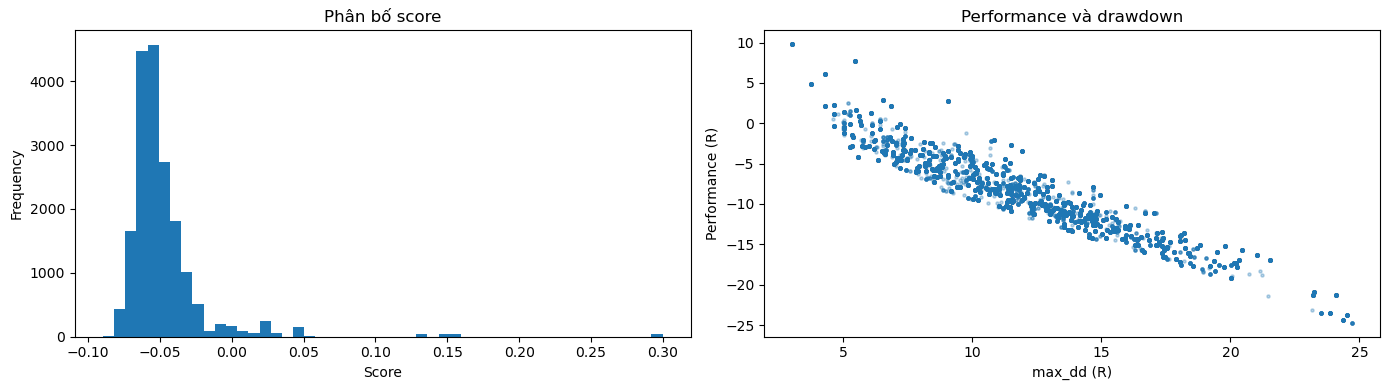

In [22]:
# Biểu đồ: phân bố score và hiệu quả theo drawdown
if ranked.empty:
    print("Không có score hợp lệ để vẽ")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    ranked["score"].plot.hist(ax=axes[0], bins=50, title="Phân bố score")
    axes[0].set_xlabel("Score")
    axes[1].scatter(ranked["max_dd"], ranked["performance"], s=5, alpha=0.3)
    axes[1].set(xlabel="max_dd (R)", ylabel="Performance (R)", title="Performance và drawdown")
    plt.tight_layout()
    plt.show()

Giai đoạn backtest: 2023-01-02 06:00:00 đến 2024-12-31 21:00:00
Tham số: {'boll_window': 40.0, 'boll_window_dev': 1.8, 'rsi_window': 5.0, 'rsi_threshold': 5.0, 'sl_multiplier': 0.6, 'tp_sl_ratio': 1.1, 'entry_mode': 1.0}


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,entry_mode,performance,max_dd,avg_dd,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
backtest_trial,40,1.8,5,5,0.6,1.1,1,9.792269,3.02,0.79,...,1.36278,0.299749,0.355124,4.051682,0.17331,40,1,23,0.299749,r_martin_monthly


,số lệnh
outcome,
take_profit,28
stop,11
timeout,1


,entry_index,entry_timestamp,exit_index,close_timestamp,entry_price,risk,stop_loss,take_profit,tp_r,holding_bars,open_at_entry,outcome,gross_r,entry_fee,holding_fee,net_r
0,107,2023-01-06 17:00:00,128,2023-01-09 14:00:00,1.063770,0.009748,1.073518,1.053047,1.1,21,1,stop,-1.0,0.109126,0.028646,-1.137771
1,296,2023-01-18 14:00:00,299,2023-01-18 17:00:00,1.086395,0.005720,1.092115,1.080103,1.1,3,1,take_profit,1.1,0.189939,0.007123,0.902939
2,360,2023-01-23 06:00:00,393,2023-01-24 15:00:00,1.090070,0.005885,1.095955,1.083597,1.1,33,1,take_profit,1.1,0.185230,0.076407,0.838363
3,540,2023-02-01 18:00:00,541,2023-02-01 19:00:00,1.091750,0.005863,1.097613,1.085301,1.1,1,1,stop,-1.0,0.186212,0.002328,-1.188540
4,747,2023-02-14 09:00:00,775,2023-02-15 13:00:00,1.076125,0.006258,1.082383,1.069241,1.1,28,1,take_profit,1.1,0.171961,0.060186,0.867852
5,991,2023-02-28 13:00:00,1002,2023-03-01 00:00:00,1.063145,0.005737,1.068882,1.056835,1.1,11,1,take_profit,1.1,0.185324,0.025482,0.889194
6,1017,2023-03-01 15:00:00,1039,2023-03-02 13:00:00,1.067225,0.006908,1.074133,1.059626,1.1,22,1,take_profit,1.1,0.154496,0.042486,0.903018
7,1192,2023-03-12 21:00:00,1254,2023-03-15 11:00:00,1.069820,0.007853,1.077673,1.061182,1.1,62,1,take_profit,1.1,0.136231,0.105579,0.858190
8,1295,2023-03-17 04:00:00,1326,2023-03-20 11:00:00,1.064930,0.005693,1.070623,1.058668,1.1,31,1,stop,-1.0,0.187059,0.072485,-1.259544
9,1328,2023-03-20 13:00:00,1350,2023-03-21 11:00:00,1.072375,0.005610,1.077985,1.066204,1.1,22,1,stop,-1.0,0.191163,0.052570,-1.243732


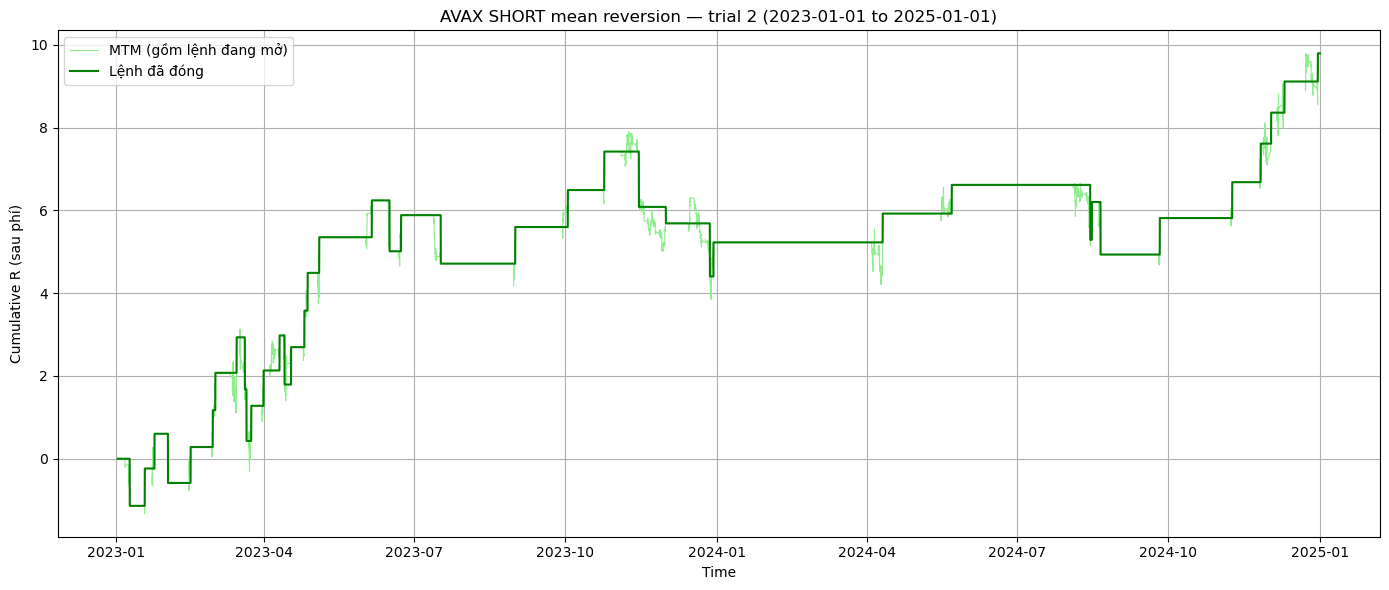

In [23]:
# Điền ID của trial trong bảng `result` (đếm từ 0), rồi chạy riêng ô này. None = bộ đứng đầu `ranked`.
TRIAL_ID = None
BACKTEST_START_DATE = None  # Ví dụ "2025-07-01"; None = ngày bắt đầu train
BACKTEST_END_DATE = None    # Ví dụ "2026-01-14"; None = ngày kết thúc train

if TRIAL_ID is None:
    if ranked.empty:
        raise ValueError("Bảng ranked rỗng; hãy điền TRIAL_ID")
    TRIAL_ID = int(ranked.index[0])
if TRIAL_ID not in result.index:
    raise KeyError(f"TRIAL_ID={TRIAL_ID} không có trong result.index")
params = grid.loc[TRIAL_ID].to_dict()
backtest_start = BACKTEST_START_DATE or start_date
backtest_end = BACKTEST_END_DATE or end_date
backtest_bars = (bars if BACKTEST_START_DATE is None and BACKTEST_END_DATE is None
                 else strategy.load_bars(csv_path, TIMEFRAME, backtest_start, backtest_end))

# GPU cho đúng một bộ tham số, và replay float64 liệt kê từng lệnh; hai bên phải khớp.
backtest_result, _ = strategy.run_gpu_grid(
    backtest_bars, grid.loc[[TRIAL_ID]].reset_index(drop=True), TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS, fee_bars=FEE_BARS, score_formula=SCORE_FORMULA)
backtest_trial = backtest_result.iloc[0]
trades = strategy.cpu_trace(backtest_bars, params, TIMEFRAME, MAX_HOLDING_BARS, FEE_BARS)
replay = strategy.trade_metrics(backtest_bars, trades, TIMEFRAME, FEE_BARS)
if replay["number_of_trade"] != int(backtest_trial["number_of_trade"]):
    print(f"Lưu ý: GPU {int(backtest_trial['number_of_trade'])} lệnh, replay float64 {replay['number_of_trade']} "
          "(giá sát ngưỡng làm tròn fp32)")

print(f"Giai đoạn backtest: {backtest_bars['timestamp'].iloc[0]} đến {backtest_bars['timestamp'].iloc[-1]}")
print("Tham số:", params)
display(backtest_trial.to_frame(name="backtest_trial").T)
display(trades["outcome"].value_counts().to_frame("số lệnh"))
display(trades.head(20))

if trades.empty:
    print("Không có lệnh nào trong khoảng backtest")
else:
    equity = strategy.mtm_equity(backtest_bars, trades, TIMEFRAME, FEE_BARS)
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(equity["timestamp"], equity["mtm_equity"], color="lightgreen", linewidth=0.8, label="MTM (gồm lệnh đang mở)")
    ax.plot(equity["timestamp"], equity["closed_equity"], color="green", label="Lệnh đã đóng")
    ax.set(xlabel="Time", ylabel="Cumulative R (sau phí)",
           title=f"AVAX SHORT mean reversion — trial {TRIAL_ID} ({backtest_start} to {backtest_end})")
    ax.legend()
    ax.grid(True)
    fig.tight_layout()
    plt.show()

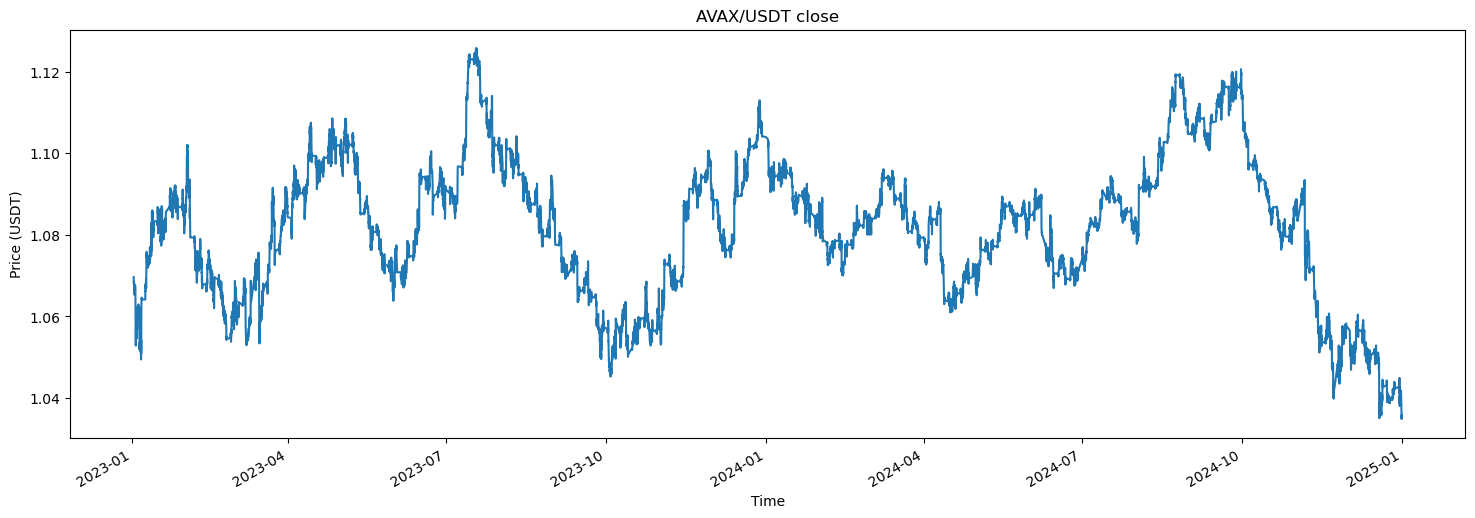

In [24]:
ax = backtest_bars.set_index("timestamp")["close"].plot(figsize=(18, 6))
ax.set(title="AVAX/USDT close", xlabel="Time", ylabel="Price (USDT)")
plt.show()